# Celda 0: Preparar el entorno
#### Configurar notebook para que encuentre los scripts del trabajo

In [1]:
# Recargar automaticamente los scripts de src/
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Verificar que estamos ejecutando desde notebooks/
SRC = Path("../src").resolve()

if not SRC.is_dir():
    raise FileNotFoundError(
        "No se encontro ../src/. "
        "Abre el notebook desde la carpeta notebooks/."
    )

# Permitir importar scripts de src/
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Definir rutas del proyecto
DATA = Path("../data")
PROC = DATA / "processed"
RAW = DATA / "raw"

RESULTS = Path("../results")
TABLES = RESULTS / "tables"
FIGURES = RESULTS / "figures"

# Crear carpetas de salida
PROC.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

print("Entorno preparado correctamente")
print("Scripts:", SRC)
print("Datos procesados:", PROC.resolve())
print("Tablas:", TABLES.resolve())
print("Figuras:", FIGURES.resolve())

Entorno preparado correctamente
Scripts: C:\Users\omarrm\OneDrive\Documentos\biopython\Plant_pathogen_interaction\src
Datos procesados: C:\Users\omarrm\OneDrive\Documentos\biopython\Plant_pathogen_interaction\data\processed
Tablas: C:\Users\omarrm\OneDrive\Documentos\biopython\Plant_pathogen_interaction\results\tables
Figuras: C:\Users\omarrm\OneDrive\Documentos\biopython\Plant_pathogen_interaction\results\figures


# Celda 1: Obtención y procesamiento de datos KEGG
#### Consultar las asociaciones gen-ruta y normalizar identificadores

In [2]:
from kegg_analysis import fetch_kegg_associations
from kegg_analysis import normalize_kegg_associations

# Definir archivo de salida
kegg_file = PROC / "kegg_gene_pathway.tsv"

# Cargar asociaciones existentes u obtenerlas de KEGG
if kegg_file.exists():
    print("Cargando asociaciones KEGG existentes...")
    kegg_associations_df = pd.read_csv(kegg_file, sep="\t")
else:
    print("Consultando asociaciones en KEGG...")
    kegg_associations_df = fetch_kegg_associations(organism_code="pst")
    kegg_associations_df.to_csv(kegg_file, sep="\t", index=False)

# Normalizar identificadores
normalized_kegg_df = normalize_kegg_associations(kegg_associations_df)

# Validar resultados
print("\nNumero de asociaciones:", len(normalized_kegg_df))

print("Genes unicos:", normalized_kegg_df["locus_key"].nunique())
print("Rutas unicas:", normalized_kegg_df["kegg_pathway"].nunique())

display(normalized_kegg_df.head())

Cargando asociaciones KEGG existentes...

Numero de asociaciones: 5029
Genes unicos: 1823
Rutas unicas: 138


,kegg_gene,kegg_pathway,locus_key
0,pst:PSPTO_0083,pst00010,PSPTO0083
1,pst:PSPTO_0239,pst00010,PSPTO0239
2,pst:PSPTO_0387,pst00010,PSPTO0387
3,pst:PSPTO_0390,pst00010,PSPTO0390
4,pst:PSPTO_0728,pst00010,PSPTO0728


# Celda 2: Integración con resultados de InMoose
#### Identificar los DEGs que tienen anotación KEGG

In [3]:
# Definir la ruta de los resultados de expresion diferencial
deg_file = TABLES / "deg_results_completa.csv"

# Cargar los resultados de InMoose
expression_df = pd.read_csv(deg_file)

# Verificar que las columnas necesarias esten presentes
required_columns = {
    "locus_key",
    "log2FoldChange",
    "adj_pvalue"
}

missing_columns = required_columns - set(expression_df.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas en los resultados: {missing_columns}")

# Integrar los resultados de expresion con las asociaciones KEGG
annotated_genes_df = expression_df.merge(
    normalized_kegg_df,
    on="locus_key",
    how="inner",
    validate="one_to_many"
)

# Identificar genes diferencialmente expresados
deg_mask = (
    (annotated_genes_df["adj_pvalue"] < 0.05)
    & (annotated_genes_df["log2FoldChange"].abs() > 1)
)

annotated_degs_df = annotated_genes_df.loc[deg_mask].copy()

# Mostrar un resumen
print("Genes evaluados en InMoose:", expression_df["locus_key"].nunique())
print("Genes evaluados con anotacion KEGG:", annotated_genes_df["locus_key"].nunique())
print("DEGs con anotacion KEGG:", annotated_degs_df["locus_key"].nunique())
print("Asociaciones gen-ruta de los DEGs:", len(annotated_degs_df))


display(annotated_degs_df.head())

Genes evaluados en InMoose: 5394
Genes evaluados con anotacion KEGG: 1735
DEGs con anotacion KEGG: 525
Asociaciones gen-ruta de los DEGs: 1523


,locus_key,baseMean,log2FoldChange,lfcSE,stat,pvalue,adj_pvalue,regulacion,gene,final_product,replicon,kegg_gene,kegg_pathway
0,PSPTO1232,12073.882594,6.31495,0.226863,27.835915,1.595180e-170,1.584652e-167,inducido,NaN,mannose-1-phosphate guanylyltransferase/mannos...,NC_004578.1,pst:PSPTO_1232,pst00051
1,PSPTO1232,12073.882594,6.31495,0.226863,27.835915,1.595180e-170,1.584652e-167,inducido,NaN,mannose-1-phosphate guanylyltransferase/mannos...,NC_004578.1,pst:PSPTO_1232,pst00520
2,PSPTO1232,12073.882594,6.31495,0.226863,27.835915,1.595180e-170,1.584652e-167,inducido,NaN,mannose-1-phosphate guanylyltransferase/mannos...,NC_004578.1,pst:PSPTO_1232,pst00541
3,PSPTO1232,12073.882594,6.31495,0.226863,27.835915,1.595180e-170,1.584652e-167,inducido,NaN,mannose-1-phosphate guanylyltransferase/mannos...,NC_004578.1,pst:PSPTO_1232,pst01100
4,PSPTO1232,12073.882594,6.31495,0.226863,27.835915,1.595180e-170,1.584652e-167,inducido,NaN,mannose-1-phosphate guanylyltransferase/mannos...,NC_004578.1,pst:PSPTO_1232,pst01110


# Celda 3: Análisis de enriquecimiento (ORA)
#### Ejecutar la prueba hipergeométrica y corregir los valores p

In [ ]:
# Definir el universo de genes con anotacion KEGG
background_genes = set(annotated_genes_df["locus_key"])

# Identificar los DEGs con anotacion KEGG
deg_genes = set(annotated_degs_df["locus_key"])

# Separar los DEGs segun su direccion de expresion
upregulated_genes = set(
    annotated_degs_df.loc[
        annotated_degs_df["log2FoldChange"] > 1,
        "locus_key"
    ]
)
downregulated_genes = set(
    annotated_degs_df.loc[
        annotated_degs_df["log2FoldChange"] < -1,
        "locus_key"
    ]
)
# Mostrar los tamanos de los conjuntos
print("Universo de referencia:", len(background_genes))
print("DEGs totales:", len(deg_genes))
print("DEGs inducidos:", len(upregulated_genes))
print("DEGs reprimidos:", len(downregulated_genes))

# Verificar que los conjuntos sean consistentes
assert deg_genes == upregulated_genes | downregulated_genes
assert upregulated_genes.isdisjoint(downregulated_genes)
assert deg_genes.issubset(background_genes)

# Celda 4:  Análisis de sobrerrepresentación de rutas KEGG

In [ ]:
from kegg_analysis import fetch_kegg_pathway_names

# Definir la ruta del catalogo de rutas KEGG
pathway_file = PROC / "kegg_pathways.tsv"

# Cargar el catalogo existente o consultarlo en KEGG
if pathway_file.exists():
    print("Cargando nombres de rutas KEGG existentes...")
    pathway_names_df = pd.read_csv(pathway_file, sep="\t")
else:
    print("Consultando nombres de rutas en KEGG...")
    pathway_names_df = fetch_kegg_pathway_names(organism_code="pst")
    # Guardar el catalogo con los nombres de columnas actualizados
    pathway_names_df.to_csv(pathway_file, sep="\t", index=False)

# Renombrar columnas antiguas
pathway_names_df = pathway_names_df.rename(
    columns={"nombre_ruta": "pathway_name"}
)
# Normalizar los identificadores
pathway_names_df["kegg_pathway"] = (
    pathway_names_df["kegg_pathway"]
    .str.replace(r"^path:", "", regex=True)
)
# Preparar las asociaciones del universo de referencia
pathway_universe_df = (
    normalized_kegg_df.loc[
        normalized_kegg_df["locus_key"].isin(background_genes)
    ]
    .drop_duplicates(subset=["locus_key", "kegg_pathway"])
    .merge(
        pathway_names_df[
            ["kegg_pathway", "pathway_name"]
        ].drop_duplicates(subset=["kegg_pathway"]),
        on="kegg_pathway",
        how="left",
        validate="many_to_one"
    )
)

# Verificar los resultados
print("Genes del universo:", pathway_universe_df["locus_key"].nunique())
print("Rutas evaluables:", pathway_universe_df["kegg_pathway"].nunique())
print("Asociaciones sin nombre:", pathway_universe_df["pathway_name"].isna().sum())

display(pathway_universe_df.head())

In [ ]:
from kegg_analysis import run_kegg_enrichment

# Ejecutar ORA para todos los DEGs
ora_all_df = run_kegg_enrichment(
    target_genes=deg_genes,
    pathway_universe_df=pathway_universe_df
)

# Ejecutar ORA para los genes inducidos
ora_up_df = run_kegg_enrichment(
    target_genes=upregulated_genes,
    pathway_universe_df=pathway_universe_df
)

# Ejecutar ORA para los genes reprimidos
ora_down_df = run_kegg_enrichment(
    target_genes=downregulated_genes,
    pathway_universe_df=pathway_universe_df
)

# Comprobar que se generaron los tres DataFrames
print("ORA total:", ora_all_df.shape)
print("ORA inducidos:", ora_up_df.shape)
print("ORA reprimidos:", ora_down_df.shape)

# Celda 5: Exportación de resultados del análisis ORA
#### Se almacenan los resultados del enriquecimiento de rutas KEGG para los tres conjuntos de genes: totales, inducidos y reprimidos.

In [ ]:
# Definir los resultados de los tres analisis
ora_results = {
    "all": ora_all_df,
    "upregulated": ora_up_df,
    "downregulated": ora_down_df
}

# Guardar las tablas completas
for analysis_name, results_df in ora_results.items():
    output_file = TABLES / f"ora_{analysis_name}.csv"
    results_df.to_csv(output_file,index=False)
    print(f"Archivo guardado: {output_file}")

# Recuperar las rutas significativamente enriquecidas
significant_results = []

for analysis_name, results_df in ora_results.items():
    significant_df = results_df.loc[
        results_df["padj"] < 0.05
    ].copy()
    significant_df["analysis_group"] = analysis_name
    significant_results.append(significant_df)

# Combinar las rutas significativas de los tres analisis
significant_pathways_df = pd.concat(significant_results, ignore_index=True)

# Guardar la tabla de rutas significativas
significant_file = TABLES / "ora_significant_pathways.csv"
significant_pathways_df.to_csv(significant_file, index=False)
print("\nTotal de registros significativos:",len(significant_pathways_df))

display(significant_pathways_df)

# Celda 6: Verificación archivos guardados

In [ ]:
 # Verificar que los archivos se guardaron correctamente
for analysis_name in ora_results:
    output_file = TABLES / f"ora_{analysis_name}.csv"
    assert output_file.exists(), ( f"No se encontro el archivo: {output_file}")
    print(f"{output_file.name}: guardado correctamente")

assert significant_file.exists()

# Mostrar el numero de rutas significativas por analisis
print("\nResumen de rutas significativas:")
print(significant_pathways_df["analysis_group"]
    .value_counts()
    .reindex(ora_results.keys(), fill_value=0)
)

ora_all.csv: guardado correctamente
ora_upregulated.csv: guardado correctamente
ora_downregulated.csv: guardado correctamente

Resumen de rutas significativas:
analysis_group
all              1
upregulated      5
downregulated    3
Name: count, dtype: int64


# Celda 7: Visualización de las rutas KEGG enriquecidas
#### Representan las rutas significativamente enriquecidas mediante un dot plot, utilizando el número de genes asociados y la significancia estadística ajustada.

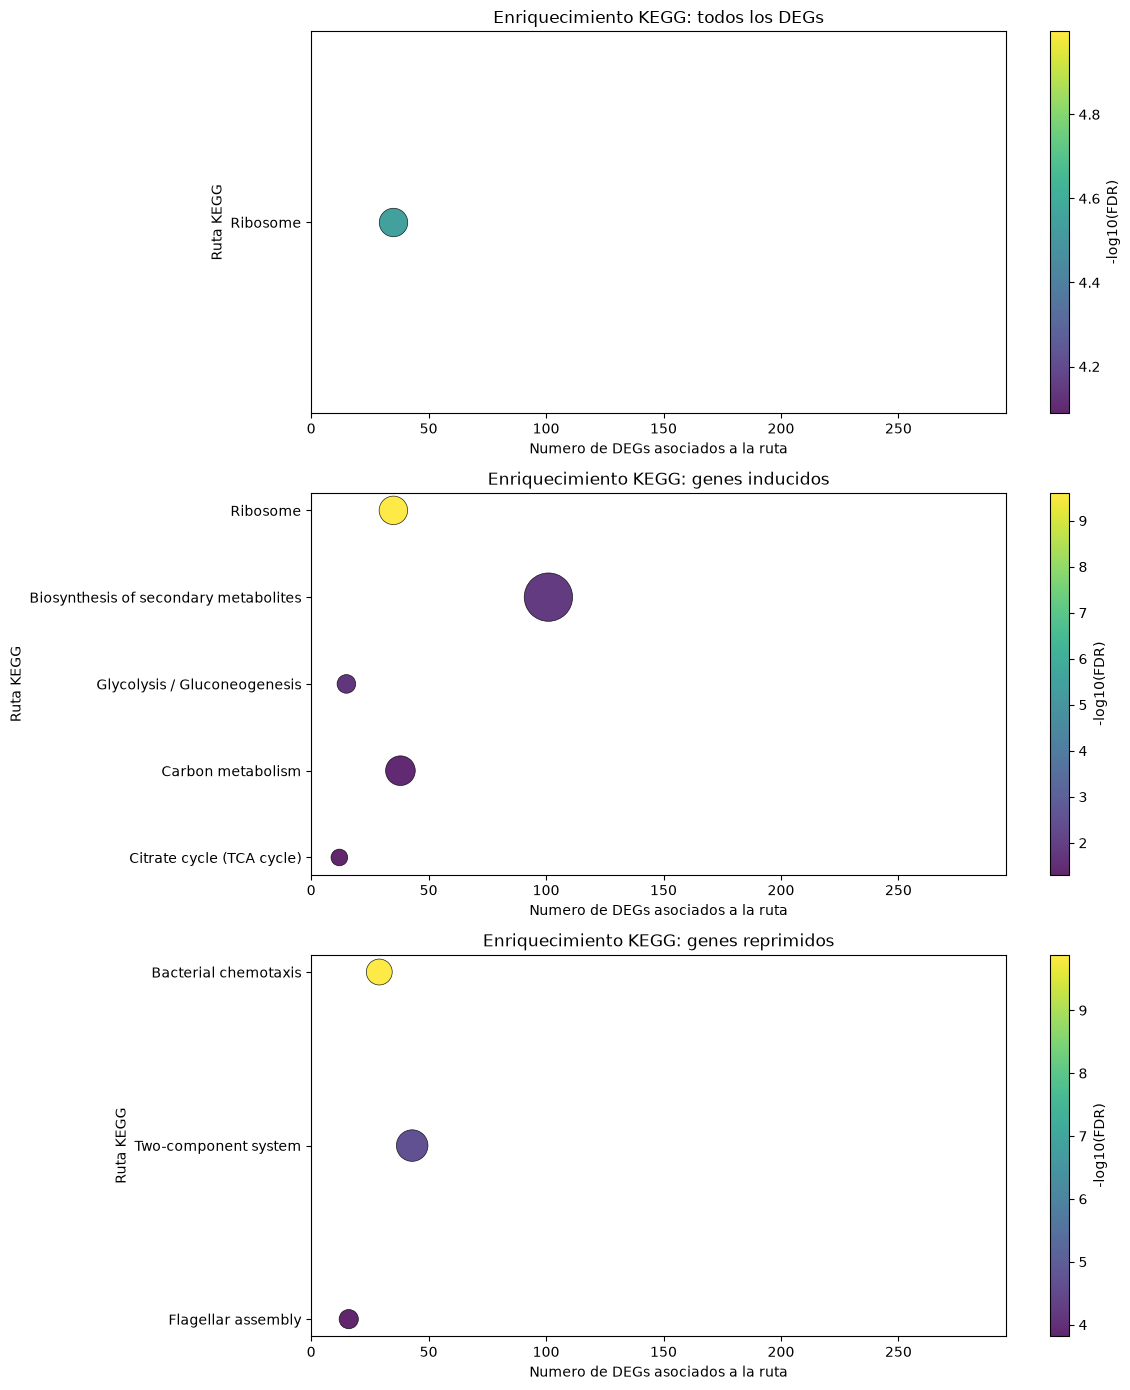

Figura guardada en: ..\results\figures\kegg_enrichment_dotplot.png


In [ ]:
from visualization import plot_kegg_enrichment

# Generar una figura con los tres analisis
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 14)
)
plot_kegg_enrichment(
    ora_all_df,
    "Enriquecimiento KEGG: todos los DEGs",
    ax=axes[0]
)
plot_kegg_enrichment(
    ora_up_df,
    "Enriquecimiento KEGG: genes inducidos",
    ax=axes[1]
)
plot_kegg_enrichment(
    ora_down_df,
    "Enriquecimiento KEGG: genes reprimidos",
    ax=axes[2]
)
# Utilizar una escala horizontal común en los tres paneles
max_overlap = max(
    ora_all_df["overlap_count"].max(),
    ora_up_df["overlap_count"].max(),
    ora_down_df["overlap_count"].max()
)
for ax in axes:
    ax.set_xlim(0, max_overlap * 1.1)

plt.tight_layout()

# Guardar la figura
figure_file = FIGURES / "kegg_enrichment_dotplot.png"
fig.savefig(
    figure_file,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figura guardada en:", figure_file)


